# Đánh giá & Kiểm thử Thuật toán KudaNN (KNN Song song hóa trên CUDA/GPU)

Notebook này thực hiện các bước kiểm chứng và benchmark theo đúng quy trình trong báo cáo *"Paralleled K-Nearest Neighbors Algorithm"*:
1. **Kiểm tra môi trường phần cứng (GPU/CUDA) & Thư viện**.
2. **Kiểm thử tính đúng đắn (Correctness Test)** trên tập dữ liệu Iris (so sánh `SequentialKNN`, `CudaKNN` với `scikit-learn` baseline).
3. **Đo thời gian thực thi (CPU vs CUDA)** theo các kích thước mẫu tăng dần (`728`, `2912`, `3751`, `5824`, `7111`, `11648`).
4. **Tính toán & vẽ biểu đồ Hệ số tăng tốc (Acceleration)** của CUDA so với CPU.
5. **Khảo sát cấu hình số lượng Threads/Block** (`16`, `32`, `64`, `128`, `256`) trên tập dữ liệu cố định.

# chuẩn bị

In [1]:
import time
import math
import numpy as np
from numba import cuda
from sklearn.metrics import accuracy_score
from sklearn.neighbors import KNeighborsClassifier

# --- 1. Sequential KNN & Sklearn Baseline ---
class SequentialKNN:
    def __init__(self, k=3):
        self.k = k
        self.X_train = None
        self.y_train = None

    def fit(self, X_train, y_train):
        self.X_train = np.array(X_train)
        self.y_train = np.array(y_train)
        return self

    def _predict_single(self, x):
        distances = np.sqrt(np.sum((self.X_train - x) ** 2, axis=1))
        sorted_indices = np.argsort(distances)
        k_indices = sorted_indices[:self.k]
        k_nearest_labels = self.y_train[k_indices]
        vals, counts = np.unique(k_nearest_labels, return_counts=True)
        return vals[np.argmax(counts)]

    def predict(self, X_test):
        X_test = np.array(X_test)
        return np.array([self._predict_single(x) for x in X_test])


class SklearnKNNBaseline:
    def __init__(self, k=3):
        self.model = KNeighborsClassifier(n_neighbors=k)

    def fit(self, X_train, y_train):
        self.model.fit(X_train, y_train)
        return self

    def predict(self, X_test):
        return self.model.predict(X_test)


# --- 2. CUDA KNN Kernel & Manager ---
@cuda.jit
def knn_cuda_kernel(X_train, y_train, n_train, X_test, n_test, n_features, k, predictions, dist_buffer, label_buffer):
    idx = cuda.grid(1)
    if idx < n_test:
        for i in range(n_train):
            dist = 0.0
            for f in range(n_features):
                diff = X_train[i, f] - X_test[idx, f]
                dist += diff * diff
            # Dùng trực tiếp math.sqrt (numba hỗ trợ math.sqrt trong cuda mode)
            dist_buffer[idx, i] = math.sqrt(dist)
            label_buffer[idx, i] = y_train[i]

        for i in range(k):
            min_idx = i
            for j in range(i + 1, n_train):
                if dist_buffer[idx, j] < dist_buffer[idx, min_idx]:
                    min_idx = j
            if min_idx != i:
                tmp_dist = dist_buffer[idx, i]
                dist_buffer[idx, i] = dist_buffer[idx, min_idx]
                dist_buffer[idx, min_idx] = tmp_dist
                tmp_lbl = label_buffer[idx, i]
                label_buffer[idx, i] = label_buffer[idx, min_idx]
                label_buffer[idx, min_idx] = tmp_lbl

        best_label = label_buffer[idx, 0]
        best_count = 0
        for i in range(k):
            current_label = label_buffer[idx, i]
            count = 0
            for j in range(k):
                if label_buffer[idx, j] == current_label:
                    count += 1
            if count > best_count:
                best_count = count
                best_label = current_label

        predictions[idx] = best_label


class CudaKNN:
    def __init__(self, k=3, threads_per_block=256):
        self.k = k
        self.threads_per_block = threads_per_block
        self.X_train = None
        self.y_train = None

    def fit(self, X_train, y_train):
        self.X_train = np.ascontiguousarray(X_train, dtype=np.float32)
        self.y_train = np.ascontiguousarray(y_train, dtype=np.int32)
        return self

    def predict(self, X_test):
        if not cuda.is_available():
            raise RuntimeError("Không tìm thấy GPU hỗ trợ CUDA!")
        X_test = np.ascontiguousarray(X_test, dtype=np.float32)
        n_train, n_features = self.X_train.shape
        n_test = X_test.shape[0]

        d_X_train = cuda.to_device(self.X_train)
        d_y_train = cuda.to_device(self.y_train)
        d_X_test = cuda.to_device(X_test)
        d_predictions = cuda.device_array(n_test, dtype=np.int32)
        d_dist_buffer = cuda.device_array((n_test, n_train), dtype=np.float32)
        d_label_buffer = cuda.device_array((n_test, n_train), dtype=np.int32)

        blocks = (n_test + self.threads_per_block - 1) // self.threads_per_block
        knn_cuda_kernel[blocks, self.threads_per_block](
            d_X_train, d_y_train, n_train, d_X_test, n_test, n_features,
            self.k, d_predictions, d_dist_buffer, d_label_buffer
        )
        cuda.synchronize()
        return d_predictions.copy_to_host()


# --- 3. Unified Interface ---
class KudaNNClassifier:
    def __init__(self, k=3, mode="cuda", threads_per_block=256):
        self.k = k
        self.mode = mode.lower()
        self.threads_per_block = threads_per_block

        if self.mode == "cuda":
            self._model = CudaKNN(k=self.k, threads_per_block=self.threads_per_block)
        elif self.mode == "cpu":
            self._model = SequentialKNN(k=self.k)
        elif self.mode == "sklearn":
            self._model = SklearnKNNBaseline(k=self.k)
        else:
            raise ValueError("Mode không hợp lệ! Chọn 'cuda', 'cpu' hoặc 'sklearn'.")

    def fit(self, X_train, y_train):
        self._model.fit(X_train, y_train)
        return self

    def predict(self, X_test):
        return self._model.predict(X_test)

    def predict_with_timing(self, X_test):
        start = time.perf_counter()
        preds = self.predict(X_test)
        return preds, time.perf_counter() - start

    def score(self, X_test, y_test):
        return accuracy_score(y_test, self.predict(X_test))

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from numba import cuda
from sklearn.datasets import load_iris, make_classification
from sklearn.model_selection import train_test_split

# Kiểm tra trạng thái GPU/CUDA trên Kaggle
print("CUDA Available:", cuda.is_available())
if cuda.is_available():
    device = cuda.get_current_device()
    # Sửa lại ở đây: gọi trực tiếp device.name vì nó đã là chuỗi (str)
    print("Device Name:", device.name)
    print("Compute Capability:", device.compute_capability)
    print("Multiprocessor Count:", device.MULTIPROCESSOR_COUNT)

# --- Kiểm tra nhanh tính đúng đắn với KudaNNClassifier ---
iris = load_iris()
X_train, X_test, y_train, y_test = train_test_split(
    iris.data, iris.target, test_size=0.3, random_state=42
)

# Khởi tạo mô hình chạy trên CUDA GPU
clf = KudaNNClassifier(k=3, mode='cuda')
clf.fit(X_train, y_train)

# Dự đoán và đo thời gian
preds, t_cuda = clf.predict_with_timing(X_test)
acc = clf.score(X_test, y_test)

print(f"\n[KudaNN CUDA Test]")
print(f"Accuracy: {acc:.4f}")
print(f"Execution Time: {t_cuda:.6f} seconds")

CUDA Available: True
Device Name: Tesla T4
Compute Capability: ComputeCapability(major=7, minor=5)
Multiprocessor Count: 40


/usr/local/lib/python3.13/dist-packages/numba_cuda/numba/cuda/dispatcher.py:716: NumbaPerformanceWarning: Grid size 1 will likely result in GPU under-utilization due to low occupancy.
  warn(errors.NumbaPerformanceWarning(msg))



[KudaNN CUDA Test]
Accuracy: 1.0000
Execution Time: 1.847501 seconds


## 1. Kiểm thử tính đúng đắn trên tập dữ liệu Iris
Đảm bảo cả phiên bản tuần tự (CPU) và song song (CUDA) đều cho độ chính xác tương đương chuẩn `scikit-learn`.

In [3]:
iris = load_iris()
X_train, X_test, y_train, y_test = train_test_split(
    iris.data, iris.target, test_size=0.2, random_state=42
)

K = 3

# 1. Sklearn Baseline
clf_sklearn = KudaNNClassifier(k=K, mode='sklearn').fit(X_train, y_train)
preds_sklearn, t_sklearn = clf_sklearn.predict_with_timing(X_test)

# 2. Sequential CPU
clf_cpu = KudaNNClassifier(k=K, mode='cpu').fit(X_train, y_train)
preds_cpu, t_cpu = clf_cpu.predict_with_timing(X_test)

# 3. KudaNN (CUDA GPU)
# Chạy warm-up 1 lần để Numba biên dịch JIT kernel trước khi đo giờ thực tế
clf_cuda = KudaNNClassifier(k=K, mode='cuda', threads_per_block=256).fit(X_train, y_train)
_ = clf_cuda.predict(X_test)
preds_cuda, t_cuda = clf_cuda.predict_with_timing(X_test)

print(f"Sklearn Accuracy : {clf_sklearn.score(X_test, y_test):.6f} | Time: {t_sklearn:.6f}s")
print(f"CPU Seq Accuracy : {clf_cpu.score(X_test, y_test):.6f} | Time: {t_cpu:.6f}s")
print(f"CUDA GPU Accuracy: {clf_cuda.score(X_test, y_test):.6f} | Time: {t_cuda:.6f}s")
print("Kết quả dự đoán CPU và CUDA trùng khớp hoàn toàn:", np.array_equal(preds_cpu, preds_cuda))

Sklearn Accuracy : 1.000000 | Time: 0.004676s
CPU Seq Accuracy : 1.000000 | Time: 0.003376s
CUDA GPU Accuracy: 1.000000 | Time: 0.001400s
Kết quả dự đoán CPU và CUDA trùng khớp hoàn toàn: True


## 2. Benchmark CPU vs CUDA theo kích thước tập dữ liệu (Sample Size)
Sử dụng các mốc kích thước mẫu tương tự mục III.C.2 trong báo cáo: `[728, 2912, 3751, 5824, 7111, 11648]`.

In [4]:
sample_sizes = [728, 2912, 3751, 5824, 7111, 11648]
cpu_times = []
cuda_times = []
accelerations = []

for size in sample_sizes:
    X_syn, y_syn = make_classification(
        n_samples=size, n_features=10, n_informative=6, n_classes=3, random_state=42
    )
    X_tr, X_te, y_tr, y_te = train_test_split(X_syn, y_syn, test_size=0.3, random_state=42)

    # Đo thời gian CPU
    model_cpu = KudaNNClassifier(k=5, mode='cpu').fit(X_tr, y_tr)
    _, t_c = model_cpu.predict_with_timing(X_te)

    # Đo thời gian CUDA
    model_cuda = KudaNNClassifier(k=5, mode='cuda', threads_per_block=256).fit(X_tr, y_tr)
    _, t_g = model_cuda.predict_with_timing(X_te)

    acc = t_c / t_g
    cpu_times.append(t_c)
    cuda_times.append(t_g)
    accelerations.append(acc)
    print(f"Size={size:5d} | CPU: {t_c:7.4f}s | CUDA: {t_g:7.4f}s | Acceleration: {acc:6.2f}x")

Size=  728 | CPU:  0.0189s | CUDA:  0.0060s | Acceleration:   3.17x
Size= 2912 | CPU:  0.1679s | CUDA:  0.0244s | Acceleration:   6.89x


/usr/local/lib/python3.13/dist-packages/numba_cuda/numba/cuda/dispatcher.py:716: NumbaPerformanceWarning: Grid size 4 will likely result in GPU under-utilization due to low occupancy.
  warn(errors.NumbaPerformanceWarning(msg))
/usr/local/lib/python3.13/dist-packages/numba_cuda/numba/cuda/dispatcher.py:716: NumbaPerformanceWarning: Grid size 5 will likely result in GPU under-utilization due to low occupancy.
  warn(errors.NumbaPerformanceWarning(msg))


Size= 3751 | CPU:  0.2698s | CUDA:  0.0315s | Acceleration:   8.57x


/usr/local/lib/python3.13/dist-packages/numba_cuda/numba/cuda/dispatcher.py:716: NumbaPerformanceWarning: Grid size 7 will likely result in GPU under-utilization due to low occupancy.
  warn(errors.NumbaPerformanceWarning(msg))


Size= 5824 | CPU:  0.6260s | CUDA:  0.0467s | Acceleration:  13.40x


/usr/local/lib/python3.13/dist-packages/numba_cuda/numba/cuda/dispatcher.py:716: NumbaPerformanceWarning: Grid size 9 will likely result in GPU under-utilization due to low occupancy.
  warn(errors.NumbaPerformanceWarning(msg))


Size= 7111 | CPU:  0.9377s | CUDA:  0.0596s | Acceleration:  15.73x
Size=11648 | CPU:  2.2688s | CUDA:  0.0979s | Acceleration:  23.17x


/usr/local/lib/python3.13/dist-packages/numba_cuda/numba/cuda/dispatcher.py:716: NumbaPerformanceWarning: Grid size 14 will likely result in GPU under-utilization due to low occupancy.
  warn(errors.NumbaPerformanceWarning(msg))


## 3. Trực quan hóa kết quả (Biểu đồ Time & Acceleration)

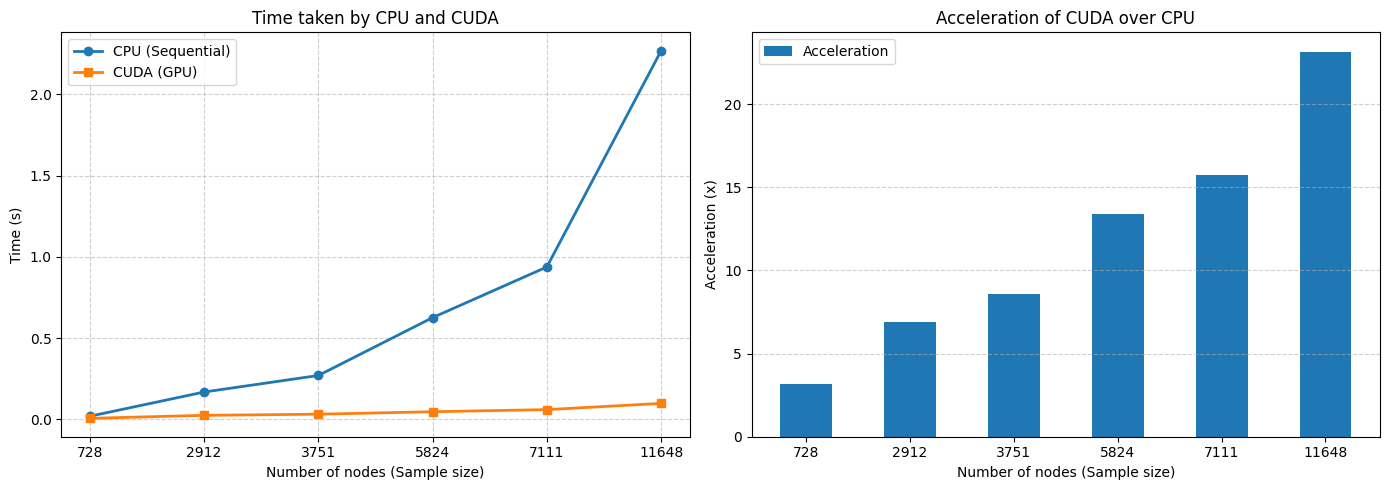

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Biểu đồ 1: Thời gian thực thi CPU vs CUDA (Tương ứng Fig. 4)
x_labels = [str(s) for s in sample_sizes]
axes[0].plot(x_labels, cpu_times, marker='o', label='CPU (Sequential)', linewidth=2)
axes[0].plot(x_labels, cuda_times, marker='s', label='CUDA (GPU)', linewidth=2)
axes[0].set_title('Time taken by CPU and CUDA')
axes[0].set_xlabel('Number of nodes (Sample size)')
axes[0].set_ylabel('Time (s)')
axes[0].legend()
axes[0].grid(True, linestyle='--', alpha=0.6)

# Biểu đồ 2: Hệ số tăng tốc Acceleration (Tương ứng Fig. 5)
axes[1].bar(x_labels, accelerations, color='tab:blue', width=0.5, label='Acceleration')
axes[1].set_title('Acceleration of CUDA over CPU')
axes[1].set_xlabel('Number of nodes (Sample size)')
axes[1].set_ylabel('Acceleration (x)')
axes[1].legend()
axes[1].grid(axis='y', linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

## 4. Khảo sát cấu hình số Threads trên mỗi Block
Cố định tập dữ liệu 7111 mẫu, thử nghiệm với các mức `threads_per_block = [16, 32, 64, 128, 256]` (Tương ứng Fig. 6).

Threads per block =  16 -> Time: 0.03378s
Threads per block =  32 -> Time: 0.03363s
Threads per block =  64 -> Time: 0.03017s
Threads per block = 128 -> Time: 0.03795s
Threads per block = 256 -> Time: 0.03337s


/usr/local/lib/python3.13/dist-packages/numba_cuda/numba/cuda/dispatcher.py:716: NumbaPerformanceWarning: Grid size 67 will likely result in GPU under-utilization due to low occupancy.
  warn(errors.NumbaPerformanceWarning(msg))
/usr/local/lib/python3.13/dist-packages/numba_cuda/numba/cuda/dispatcher.py:716: NumbaPerformanceWarning: Grid size 34 will likely result in GPU under-utilization due to low occupancy.
  warn(errors.NumbaPerformanceWarning(msg))
/usr/local/lib/python3.13/dist-packages/numba_cuda/numba/cuda/dispatcher.py:716: NumbaPerformanceWarning: Grid size 17 will likely result in GPU under-utilization due to low occupancy.
  warn(errors.NumbaPerformanceWarning(msg))


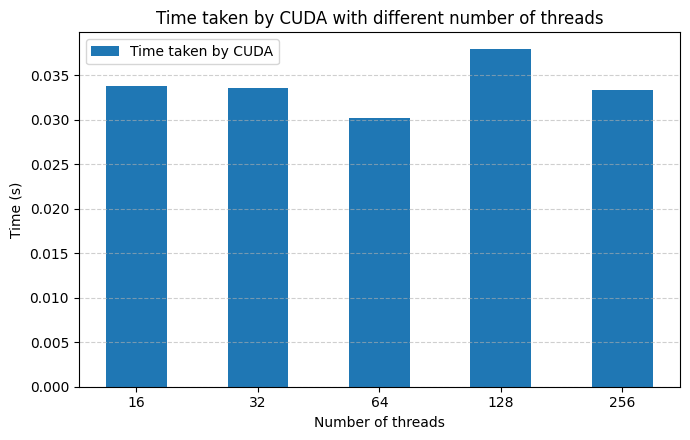

In [6]:
thread_configs = [16, 32, 64, 128, 256]
thread_times = []

X_7111, y_7111 = make_classification(
    n_samples=7111, n_features=10, n_informative=6, n_classes=3, random_state=42
)
X_tr, X_te, y_tr, y_te = train_test_split(X_7111, y_7111, test_size=0.3, random_state=42)

for tpb in thread_configs:
    model = KudaNNClassifier(k=5, mode='cuda', threads_per_block=tpb).fit(X_tr, y_tr)
    _, elapsed = model.predict_with_timing(X_te)
    thread_times.append(elapsed)
    print(f"Threads per block = {tpb:3d} -> Time: {elapsed:.5f}s")

plt.figure(figsize=(7, 4.5))
plt.bar([str(t) for t in thread_configs], thread_times, color='tab:blue', width=0.5, label='Time taken by CUDA')
plt.title('Time taken by CUDA with different number of threads')
plt.xlabel('Number of threads')
plt.ylabel('Time (s)')
plt.legend()
plt.grid(axis='y', linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()